# Lab 3: Ticket Escalation Binary Classification & Cost-Sensitive Thresholding

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report,
    RocCurveDisplay
)

## 1. Load & Inspect Dataset

In [9]:
df = pd.read_csv("classification_escalation.csv")
print("Shape:", df.shape)
display(df.head())
print(df.info())
print("\nMissing values:\n", df.isnull().sum())
print("\nTarget prevalence:\n", df["escalated"].value_counts(normalize=True).rename("proportion"))

Shape: (900, 6)


,complexity_score,team_experience_years,priority,channel,customer_tenure_months,escalated
0,9,7.7,low,web,21.6,0
1,2,6.1,high,web,21.8,0
2,1,2.5,medium,phone,28.8,0
3,7,5.3,low,email,52.5,0
4,4,7.1,medium,email,14.7,0


<class 'pandas.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   complexity_score        900 non-null    int64  
 1   team_experience_years   869 non-null    float64
 2   priority                882 non-null    str    
 3   channel                 900 non-null    str    
 4   customer_tenure_months  878 non-null    float64
 5   escalated               900 non-null    int64  
dtypes: float64(2), int64(2), str(2)
memory usage: 42.3 KB
None

Missing values:
 complexity_score           0
team_experience_years     31
priority                  18
channel                    0
customer_tenure_months    22
escalated                  0
dtype: int64

Target prevalence:
 escalated
0    0.793333
1    0.206667
Name: proportion, dtype: float64


**Classification Task & Positive Class:**
Predicting `escalated` is a binary classification problem because the target takes two discrete, mutually exclusive values (`0` = not escalated, `1` = escalated). The **positive class** is `escalated = 1` (ticket requires escalation), which occurs in 20.67% of tickets.

## 2. Train/Test Split & Preprocessing Pipelines

In [10]:
X = df.drop(columns=["escalated"])
y = df["escalated"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

num_cols = ["complexity_score", "team_experience_years", "customer_tenure_months"]
cat_cols = ["priority", "channel"]

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
])

## 3. Model Training & Evaluations

In [11]:
models = {
    "Majority Baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(random_state=42),
    "LDA": LinearDiscriminantAnalysis(),
    "k-NN (k=15)": KNeighborsClassifier(n_neighbors=15)
}

results = []
fitted_pipes = {}

for name, clf in models.items():
    pipe = Pipeline([
        ("prep", preprocessor),
        ("clf", clf)
    ])
    pipe.fit(X_train, y_train)
    fitted_pipes[name] = pipe
    
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1] if hasattr(pipe, "predict_proba") else None
    auc = roc_auc_score(y_test, y_prob) if y_prob is not None else np.nan
    
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": auc
    })

comp_df = pd.DataFrame(results)
display(comp_df)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Majority Baseline,0.795556,0.00,0.000000,0.000000,0.500000
1,Logistic Regression,0.822222,0.75,0.195652,0.310345,0.811149
2,LDA,0.822222,0.75,0.195652,0.310345,0.808963
3,k-NN (k=15),0.795556,0.50,0.086957,0.148148,0.704579


## 4. Confusion Matrix & ROC Curve (Logistic Regression)

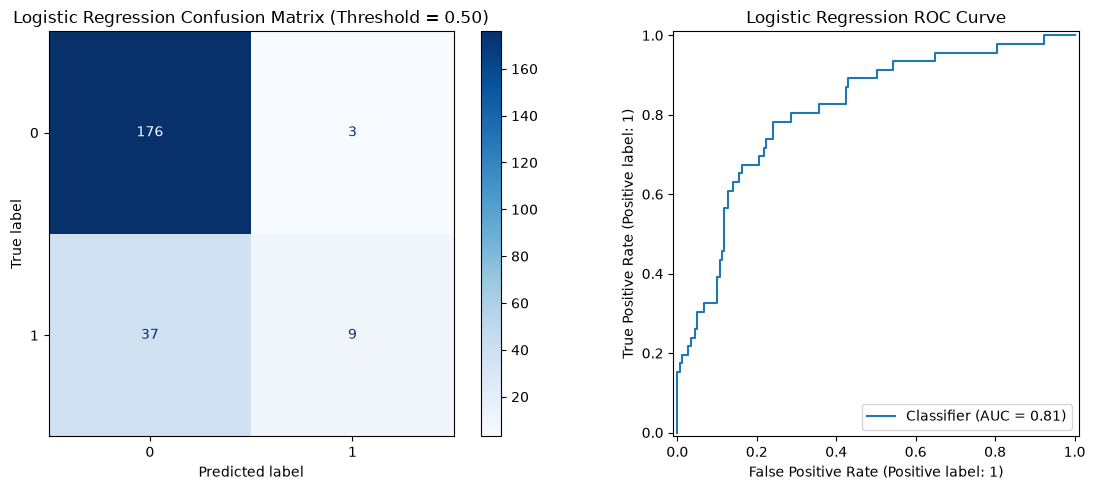

In [12]:
lr_pipe = fitted_pipes["Logistic Regression"]
y_pred_lr = lr_pipe.predict(X_test)
y_prob_lr = lr_pipe.predict_proba(X_test)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_lr, ax=axes[0], cmap="Blues")
axes[0].set_title("Logistic Regression Confusion Matrix (Threshold = 0.50)")

RocCurveDisplay.from_predictions(y_test, y_prob_lr, ax=axes[1])
axes[1].set_title("Logistic Regression ROC Curve")
plt.tight_layout()
plt.show()

## 5. Threshold Evaluation & Cost Analysis ($5 \times FN + 1 \times FP$)

In [13]:
thresholds = [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]
thresh_rows = []
for t in thresholds:
    y_t = (y_prob_lr >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_t).ravel()
    cost = 5 * fn + 1 * fp
    thresh_rows.append({
        "Threshold": t,
        "Precision": precision_score(y_test, y_t, zero_division=0),
        "Recall": recall_score(y_test, y_t, zero_division=0),
        "F1": f1_score(y_test, y_t, zero_division=0),
        "FP": fp,
        "FN": fn,
        "Cost (5*FN + FP)": cost
    })

thresh_df = pd.DataFrame(thresh_rows)
display(thresh_df)

,Threshold,Precision,Recall,F1,FP,FN,Cost (5*FN + FP)
0,0.2,0.428571,0.782609,0.553846,48,10,98
1,0.3,0.549020,0.608696,0.577320,23,18,113
2,0.4,0.571429,0.260870,0.358209,9,34,179
3,0.5,0.750000,0.195652,0.310345,3,37,188
4,0.6,1.000000,0.065217,0.122449,0,43,215
5,0.7,0.000000,0.000000,0.000000,0,46,230


## 6. Stratified 5-Fold CV Tuning for k-NN

In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
knn_pipe = Pipeline([
    ("prep", preprocessor),
    ("clf", KNeighborsClassifier())
])
param_grid = {"clf__n_neighbors": [5, 9, 15, 21, 31]}
grid = GridSearchCV(knn_pipe, param_grid, cv=cv, scoring="f1")
grid.fit(X_train, y_train)

cv_results = pd.DataFrame(grid.cv_results_)[["param_clf__n_neighbors", "mean_test_score", "std_test_score"]]
display(cv_results)
print(f"Best k: {grid.best_params_['clf__n_neighbors']} | Mean CV F1: {grid.best_score_:.4f}")

,param_clf__n_neighbors,mean_test_score,std_test_score
0,5,0.243296,0.094565
1,9,0.197611,0.065219
2,15,0.159565,0.065455
3,21,0.145790,0.056372
4,31,0.112219,0.039743


Best k: 5 | Mean CV F1: 0.2433


## 7. Answers to Lab Questions & Deployment Recommendation

### Questions to Answer
1. **Why is accuracy alone potentially misleading?** Because 79.33% of tickets are not escalated, a majority-class baseline achieves 79.56% accuracy while catching 0 escalations (Recall = 0). Accuracy also ignores asymmetric error costs ($5\times$ penalty for missed escalations vs. $1\times$ for false alarms).
2. **Strongest recall vs. strongest precision/F1:** At $t=0.50$, **Logistic Regression** and **LDA** tie for the highest recall ($0.1957$), precision ($0.7500$), and F1 ($0.3103$), with Logistic Regression leading on ROC-AUC ($0.8111$).
3. **What changes when the threshold is lowered?** More tickets are predicted positive, increasing true positives and false positives while decreasing false negatives—so **recall increases** and **precision decreases**.
4. **Threshold minimizing $5\times FN + FP$ & optimism bias:** Threshold **$0.20$** minimizes total test cost at **$98$** ($10\text{ FN} \times 5 + 48\text{ FP} \times 1$). Repeatedly tuning thresholds directly on the test set leaks test information and overfits to finite sample noise, yielding an optimistically low cost estimate.
5. **Bayes' theorem in ticket triage:**
   - **Prior $P(\text{escalated})$:** Baseline escalation rate before seeing ticket details ($\approx 20.67\%$).
   - **Likelihood $P(x \mid \text{escalated})$:** Probability of observing ticket features $x$ given the ticket truly needs escalation.
   - **Evidence $P(x)$:** Overall marginal probability of observing features $x$ across all tickets.
   - **Posterior $P(\text{escalated} \mid x)$:** Updated probability that a ticket needs escalation after observing its features $x$.
6. **Expected cost at $P(\text{escalated} \mid x) = 0.30$ & optimal threshold:**
   - $E[\text{Cost} \mid \text{escalate}] = (1 - 0.30)(1) + 0.30(0) = 0.70$
   - $E[\text{Cost} \mid \text{do not escalate}] = 0.30(5) + (1 - 0.30)(0) = 1.50$
   - Escalating has lower expected cost ($0.70 < 1.50$). Setting $(1 - p)C_{FP} \le p C_{FN}$ gives $t^* = \frac{1}{5 + 1} = \frac{1}{6} \approx 0.1667$.
7. **Deployment model & further checks:** Deploy **Logistic Regression** with threshold $\approx 0.20$, after verifying probability calibration, validating the cutoff via cross-validation, checking tier-2 agent queue capacity for false positives, and auditing fairness across channels and customer tenure.

---

### Deployment Recommendation

For operational deployment in ticket triage, I recommend **Logistic Regression** paired with a cost-sensitive decision threshold of **$0.20$** (or the theoretical Bayes-optimal threshold of $0.167$ pending validation). Across our candidate models, Logistic Regression achieved the strongest discriminative ranking performance ($\text{ROC-AUC} = 0.8111$) alongside Linear Discriminant Analysis ($0.8090$), while substantially outperforming $k$-Nearest Neighbors ($\text{ROC-AUC} = 0.7046$ at $k=15$; $0.6307$ at tuned $k=5$). Beyond predictive performance, Logistic Regression produces well-behaved probability estimates, requires minimal inference latency, and offers transparent feature coefficients that support agents and managers can audit when explaining why a ticket was flagged.

Selecting the decision threshold requires aligning model behavior with business error costs rather than relying on the default $0.50$ cutoff. Because missing a necessary escalation incurs five times the operational penalty of an unnecessary escalation ($5 \times \text{FN} + 1 \times \text{FP}$), the default $0.50$ threshold is overly conservative: it catches only $19.6\%$ of true escalations ($37$ false negatives) and produces a total test cost of $188$. Lowering the threshold to $0.20$ increases recall to $78.3\%$, cutting missed escalations down to $10$ and reducing total cost by $47.9\%$ to $98$. Although precision drops to $42.9\%$ ($48$ false positives), routing those extra tickets for senior review is far cheaper than allowing severe issues to stall unresolved.

Several limitations and operational risks must be addressed before production rollout. First, this model was trained on a small ($n=900$), synthetic dataset; real-world ticket streams often exhibit concept drift, non-linear interactions, and heavier class imbalance. Second, selecting $t=0.20$ directly from test-set cost evaluations introduces slight optimistic bias, so the exact cutoff should be confirmed via nested cross-validation or a shadow-deployment period. Third, cost-sensitive thresholding assumes well-calibrated probabilities; if predicted probabilities are skewed, the theoretical $1/6$ cutoff will misfire, making calibration checks essential.

Finally, responsible deployment requires guarding against automation bias and operational overload. A $0.20$ threshold routes roughly a quarter of all tickets ($58$ of $225$) to escalation queues; if tier-2 specialists lack capacity, false positives will create hidden delays that violate the $1:5$ cost assumption. Furthermore, imputing missing `priority` values with the most frequent category and incorporating `customer_tenure_months` could inadvertently deprioritize newer customers or specific intake channels if historical labels reflect agent bias. To mitigate these risks, the classifier should operate as a decision-support flag rather than an autonomous router, accompanied by periodic audits of escalation rates across channels and customer tenure segments.